# Analyse de convergence PINN — 4 features × 16 combinaisons

Notebook d'analyse pour les **16 configurations** issues des 4 flags binaires :

| Code | Feature |
|------|---------|
| `F` | Fourier features |
| `T` | Temporal segmentation |
| `S` | Adaptive sampling (enregistrement des points) |
| `W` | Adaptive weighting (GradNorm, enregistrement des poids) |

**Convention** : `pinn_<F><T><S><W>`, par ex. `pinn_0110` = temporal + sampling.

**Sources exploitées** (écrites par `train.py`) :
- `history.csv` / `history.json` → loss par époque
- `adaptive_history.npz` → points sélectionnés (S=1)
- `adaptive_weights.json` → poids GradNorm (W=1)
- `checkpoint_final.pt` → modèle entraîné


In [3]:
# %%
import json
import shutil
import sys
from copy import deepcopy
from dataclasses import replace
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
import torch

from IPython.display import display

ROOT = Path.cwd()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent

sys.path.insert(0, str(ROOT / "src"))
print('Répertoire du projet :', ROOT)

from config import Config
from model import SloshingPINN
from train import train
from visualization import (
    plot_history, plot_histories, load_model,
    plot_fields, plot_residuals, animate_residuals,
)

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
mpl.rcParams["figure.dpi"] = 110

OUTPUT_DIR = ROOT / "reports"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print("Output dir:", OUTPUT_DIR.resolve())


Répertoire du projet : /home/ludodo/SINN
Output dir: /home/ludodo/SINN/reports


## 1. Énumération des 16 combinaisons

In [5]:
# %%
FEATURE_NAMES = ["fourier", "sampling", "temporal", "weighting"]

def combo_name(bits):
    """Return 'model_<F><T><S><W>' from a bit tuple."""
    return "model_ff" + str(bits[0]) + "_as" + str(bits[1]) + "_ts" + str(bits[2]) + "_alw" + str(bits[3])

ALL_BITS = [
    (f, s, t, w)
    for f in (0, 1)
    for s in (0, 1)
    for t in (0, 1)
    for w in (0, 1)
]

assert len(ALL_BITS) == 16
for b in ALL_BITS:
    print(combo_name(b), dict(zip(FEATURE_NAMES, b)))


model_ff0_as0_ts0_alw0 {'fourier': 0, 'sampling': 0, 'temporal': 0, 'weighting': 0}
model_ff0_as0_ts0_alw1 {'fourier': 0, 'sampling': 0, 'temporal': 0, 'weighting': 1}
model_ff0_as0_ts1_alw0 {'fourier': 0, 'sampling': 0, 'temporal': 1, 'weighting': 0}
model_ff0_as0_ts1_alw1 {'fourier': 0, 'sampling': 0, 'temporal': 1, 'weighting': 1}
model_ff0_as1_ts0_alw0 {'fourier': 0, 'sampling': 1, 'temporal': 0, 'weighting': 0}
model_ff0_as1_ts0_alw1 {'fourier': 0, 'sampling': 1, 'temporal': 0, 'weighting': 1}
model_ff0_as1_ts1_alw0 {'fourier': 0, 'sampling': 1, 'temporal': 1, 'weighting': 0}
model_ff0_as1_ts1_alw1 {'fourier': 0, 'sampling': 1, 'temporal': 1, 'weighting': 1}
model_ff1_as0_ts0_alw0 {'fourier': 1, 'sampling': 0, 'temporal': 0, 'weighting': 0}
model_ff1_as0_ts0_alw1 {'fourier': 1, 'sampling': 0, 'temporal': 0, 'weighting': 1}
model_ff1_as0_ts1_alw0 {'fourier': 1, 'sampling': 0, 'temporal': 1, 'weighting': 0}
model_ff1_as0_ts1_alw1 {'fourier': 1, 'sampling': 0, 'temporal': 1, 'weighti

## 2. Helper : Construire une `Config` depuis les bits

Chaque run est identique au `Config` de base sauf pour les 4 flags positionnés selon le tuple `bits`.

In [ ]:
# %%
def make_cfg_from_bits(bits, base_cfg):
    """Retourne une copie de `base_cfg` avec les 4 flags positionnés."""
    f, t, s, w = bits
    updates = dict(
        use_fourier_features=bool(f),
        use_temporal_segmentation=bool(t),
        use_adaptive_sampling=bool(s),
        use_adaptive_loss_weights=bool(w),
    )
    return replace(base_cfg, **updates)


## 3. Boucle d'entraînement (16 runs)

Idempotent : les runs déjà présents (`checkpoint_final.pt`) sont sautés.  
Mets `EPOCHS_OVERRIDE` à `None` pour la config complète, à `200` pour un smoke-test.

In [ ]:
# %%
RUN_TRAINING    = True
EPOCHS_OVERRIDE = 200        # None pour cfg.epochs complet
SKIP_IF_EXISTS  = True
USE_LBFGS       = False      # False pour comparer à budget égal

base_cfg = Config()
overrides = dict(epochs=EPOCHS_OVERRIDE) if EPOCHS_OVERRIDE is not None else {}
overrides["use_lbfgs"] = USE_LBFGS
base_cfg = replace(base_cfg, **overrides)

if RUN_TRAINING:
    for bits in ALL_BITS:
        name = combo_name(bits)
        rdir = OUTPUT_DIR / name
        done = (rdir / "checkpoint_final.pt").is_file()
        if SKIP_IF_EXISTS and done:
            print(f"[skip] {name} already trained")
            continue
        cfg = make_cfg_from_bits(bits, base_cfg)
        print()
        print("=" * 70)
        print(f"Training {name}  bits={bits}")
        print("=" * 70)
        train(cfg=cfg, output_dir=OUTPUT_DIR, model_name=name, resume=False)
else:
    print("Training skipped (RUN_TRAINING=False).")


## 4. Chargement des historiques

In [6]:
# %%
histories: dict[tuple, pd.DataFrame] = {}
for bits in ALL_BITS:
    csv = ROOT / "models" / combo_name(bits) / "history.csv"
    if csv.is_file():
        histories[bits] = pd.read_csv(csv)
    else:
        print(f"[missing] {combo_name(bits)}")

print()
print(f"Loaded {len(histories)}/16 histories")



Loaded 16/16 histories


## 5. Vue globale : grille 4×4 de la loss totale

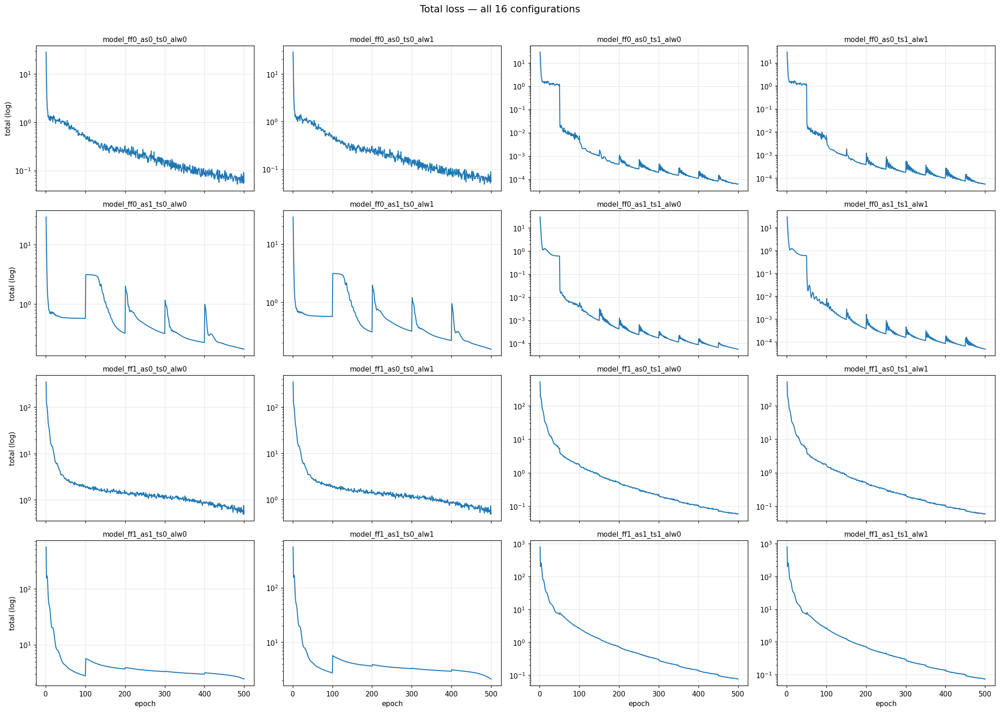

In [7]:
# %%
def plot_total_grid(histories, title="Total loss — all 16 configurations"):
    fig, axes = plt.subplots(4, 4, figsize=(20, 14), sharex=True)
    for ax, bits in zip(axes.ravel(), ALL_BITS):
        ax.set_title(combo_name(bits), fontsize=10)
        ax.grid(alpha=0.3)
        if bits not in histories:
            ax.text(0.5, 0.5, "missing", ha="center", transform=ax.transAxes)
            continue
        df = histories[bits]
        ax.semilogy(df["epoch"], df["total"].clip(lower=1e-16), lw=1.4)
    for ax in axes[-1]:
        ax.set_xlabel("epoch")
    for ax in axes[:, 0]:
        ax.set_ylabel("total (log)")
    fig.suptitle(title, y=1.01, fontsize=14)
    fig.tight_layout()
    return fig

if histories:
    fig = plot_total_grid(histories)
    plt.show()


## 6. Effet marginal de chaque feature

Pour chaque feature, les configs **ON** en rouge, **OFF** en gris, avec la moyenne géométrique en pointillés.

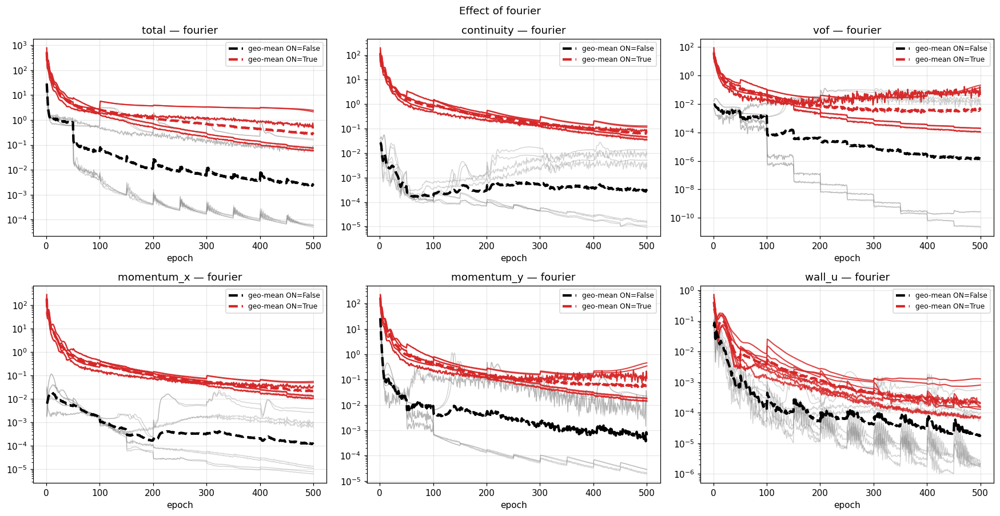

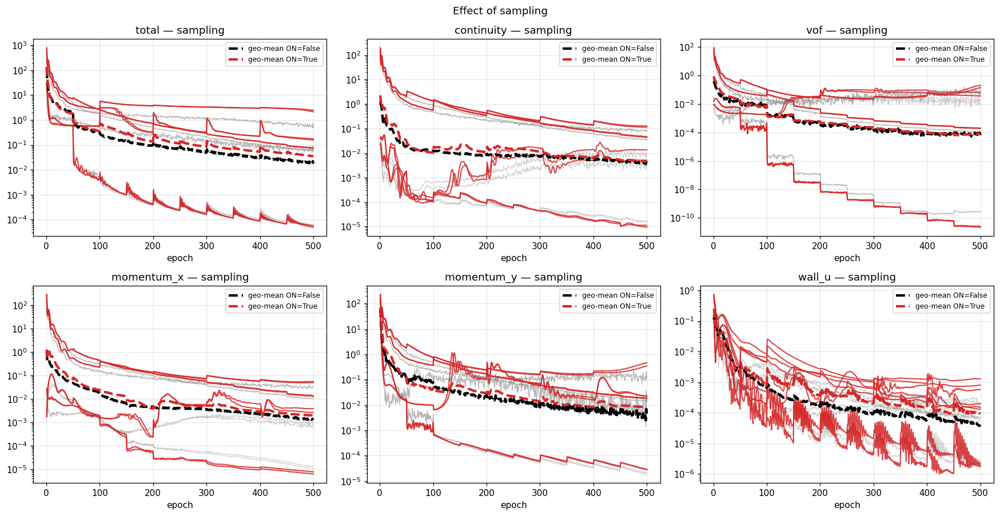

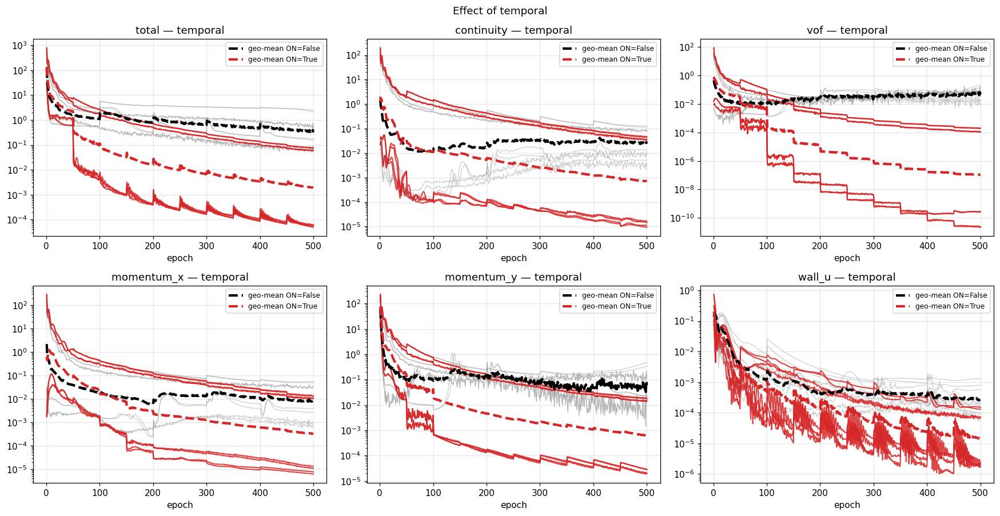

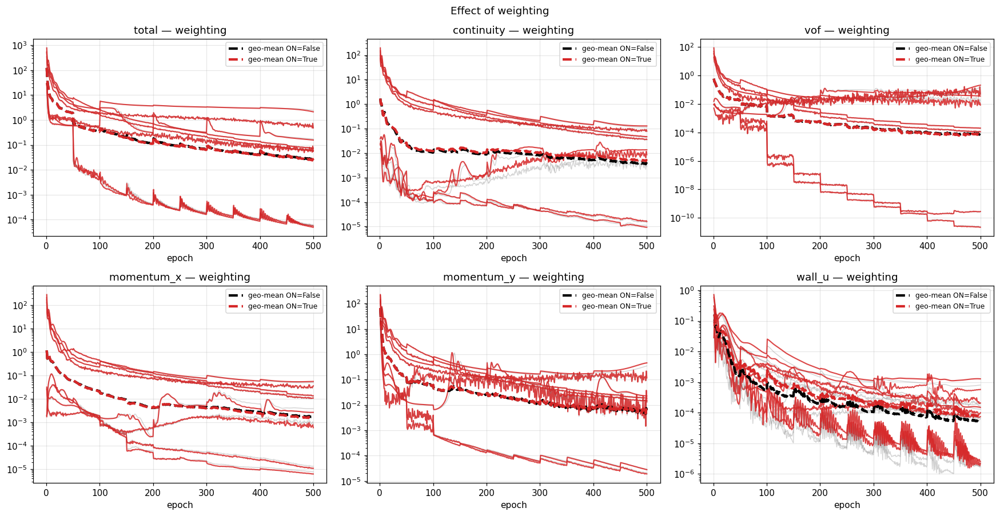

In [9]:
# %%
def plot_feature_effect(feature_idx, histories, metrics=("total",),
                        ncols=3, figsize=(16, 8)):
    label = FEATURE_NAMES[feature_idx]
    nrows = int(np.ceil(len(metrics) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=figsize, squeeze=False)
    axes = axes.ravel()

    for ax, metric in zip(axes, metrics):
        ax.grid(alpha=0.3)
        ax.set_title(f"{metric} — {label}")
        ax.set_xlabel("epoch")

        for bits, df in histories.items():
            on = bits[feature_idx] == 1
            ax.semilogy(
                df["epoch"], df[metric].clip(lower=1e-16),
                color="tab:red" if on else "tab:gray",
                alpha=0.85 if on else 0.35,
                lw=1.4 if on else 0.9,
            )

        on_list = [d.assign(_on=True) for b, d in histories.items() if b[feature_idx]]
        off_list = [d.assign(_on=False) for b, d in histories.items() if not b[feature_idx]]
        merged = pd.concat(on_list + off_list, ignore_index=True)
        merged = merged[merged[metric] > 0]
        agg = merged.groupby(["_on", "epoch"])[metric].apply(
            lambda s: np.exp(np.log(s).mean())
        ).reset_index()
        for on, sub in agg.groupby("_on"):
            ax.semilogy(sub["epoch"], sub[metric],
                        color="tab:red" if on else "black",
                        lw=2.8, ls="--", label=f"geo-mean ON={on}")
        ax.legend(fontsize=8)

    for ax in axes[len(metrics):]:
        ax.axis("off")
    fig.tight_layout()
    return fig

if histories:
    for i, fname in enumerate(FEATURE_NAMES):
        fig = plot_feature_effect(
            i, histories,
            metrics=("total", "continuity", "vof", "momentum_x",
                     "momentum_y", "wall_u"),
        )
        fig.suptitle(f"Effect of {fname}", y=1.02)
        plt.show()


## 7. Vitesse de convergence

`epochs_to_1.1m` : nombre d'époques pour atteindre `1.10 × min(total)` — un indicateur de « rapidité effective » normalisé par le minimum atteint.

In [10]:
# %%
def epochs_to_ratio(df, ratio=1.10):
    mn = df["total"].min()
    if not np.isfinite(mn) or mn <= 0:
        return len(df)
    mask = df["total"] <= ratio * mn
    if mask.any():
        return int(df.loc[mask, "epoch"].iloc[0])
    return int(df["epoch"].iloc[-1])


def speed_table(histories):
    rows = []
    for bits, df in histories.items():
        row = {name: int(b) for name, b in zip(FEATURE_NAMES, bits)}
        row["combo"] = combo_name(bits)
        row["min_total"] = float(df["total"].min())
        row["final_total"] = float(df["total"].iloc[-1])
        row["epochs_to_1.1m"] = epochs_to_ratio(df, 1.10)
        row["epochs_to_1.5m"] = epochs_to_ratio(df, 1.50)
        rows.append(row)
    return pd.DataFrame(rows).sort_values("min_total")

speed_df = speed_table(histories)
speed_df


,fourier,sampling,temporal,weighting,combo,min_total,final_total,epochs_to_1.1m,epochs_to_1.5m
7,0,1,1,1,model_ff0_as1_ts1_alw1,0.000048,0.000049,492,440
3,0,0,1,1,model_ff0_as0_ts1_alw1,0.000054,0.000054,484,439
6,0,1,1,0,model_ff0_as1_ts1_alw0,0.000056,0.000056,489,426
2,0,0,1,0,model_ff0_as0_ts1_alw0,0.000061,0.000062,484,435
1,0,0,0,1,model_ff0_as0_ts0_alw1,0.048501,0.054945,472,391
0,0,0,0,0,model_ff0_as0_ts0_alw0,0.051947,0.057481,437,391
11,1,0,1,1,model_ff1_as0_ts1_alw1,0.057816,0.058459,474,422
10,1,0,1,0,model_ff1_as0_ts1_alw0,0.058445,0.059082,474,422
15,1,1,1,1,model_ff1_as1_ts1_alw1,0.073865,0.073865,475,429
14,1,1,1,0,model_ff1_as1_ts1_alw0,0.075428,0.075428,475,429


## 8. Tableau récapitulatif + impact marginal

Comparaison de la loss finale (et du minimum) par terme, et calcul de l'effet marginal de chaque feature (ratio `mean_ON / mean_OFF` — `< 1` signifie que la feature aide).

In [11]:
# %%
SUMMARY_TERMS = [
    "total", "continuity", "vof",
    "momentum_x", "momentum_y",
    "wall_u", "wall_v", "pressure_gauge",
]

rows = []
for bits, df in histories.items():
    row = {name: int(b) for name, b in zip(FEATURE_NAMES, bits)}
    row["combo"] = combo_name(bits)
    for term in SUMMARY_TERMS:
        if term in df.columns:
            row[f"final_{term}"] = float(df[term].iloc[-1])
            row[f"min_{term}"] = float(df[term].min())
    rows.append(row)

summary_df = pd.DataFrame(rows)

impact = []
for fname in FEATURE_NAMES:
    on = summary_df[summary_df[fname] == 1]
    off = summary_df[summary_df[fname] == 0]
    impact.append({
        "feature": fname,
        "mean_final_ON": on["final_total"].mean(),
        "mean_final_OFF": off["final_total"].mean(),
        "mean_min_ON": on["min_total"].mean(),
        "mean_min_OFF": off["min_total"].mean(),
        "ratio_final_ON/OFF": on["final_total"].mean() / off["final_total"].mean(),
        "ratio_min_ON/OFF": on["min_total"].mean() / off["min_total"].mean(),
    })

impact_df = pd.DataFrame(impact)
print("=== Impact marginal (mean over configs) ===")
display(impact_df.style.format(precision=3))

print()
print("=== Détail par configuration ===")
display(
    summary_df[[
        "combo", *FEATURE_NAMES,
        "final_total", "min_total",
        "final_continuity", "final_vof",
        "final_momentum_x", "final_momentum_y",
        "final_wall_u", "final_wall_v",
    ]].sort_values("final_total").style.format(precision=3)
)


=== Impact marginal (mean over configs) ===


,feature,mean_final_ON,mean_final_OFF,mean_min_ON,mean_min_OFF,ratio_final_ON/OFF,ratio_min_ON/OFF
0,fourier,0.728,0.055,0.728,0.054,13.164,13.526
1,sampling,0.633,0.151,0.633,0.149,4.201,4.249
2,temporal,0.033,0.750,0.033,0.748,0.045,0.044
3,weighting,0.370,0.413,0.369,0.413,0.894,0.894



=== Détail par configuration ===


,combo,fourier,sampling,temporal,weighting,final_total,min_total,final_continuity,final_vof,final_momentum_x,final_momentum_y,final_wall_u,final_wall_v
7,model_ff0_as1_ts1_alw1,0,1,1,1,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
3,model_ff0_as0_ts1_alw1,0,0,1,1,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
6,model_ff0_as1_ts1_alw0,0,1,1,0,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
2,model_ff0_as0_ts1_alw0,0,0,1,0,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
1,model_ff0_as0_ts0_alw1,0,0,0,1,0.055,0.049,0.009,0.008,0.001,0.013,0.000,0.005
0,model_ff0_as0_ts0_alw0,0,0,0,0,0.057,0.052,0.003,0.015,0.001,0.013,0.000,0.001
11,model_ff1_as0_ts1_alw1,1,0,1,1,0.058,0.058,0.036,0.000,0.011,0.015,0.000,0.000
10,model_ff1_as0_ts1_alw0,1,0,1,0,0.059,0.058,0.034,0.000,0.010,0.014,0.000,0.000
15,model_ff1_as1_ts1_alw1,1,1,1,1,0.074,0.074,0.047,0.000,0.013,0.019,0.000,0.000
14,model_ff1_as1_ts1_alw0,1,1,1,0,0.075,0.075,0.044,0.000,0.013,0.018,0.000,0.000


## 9. Poids adaptatifs GradNorm (W=1)

Évolution temporelle des poids et distribution sur la seconde moitié du training.

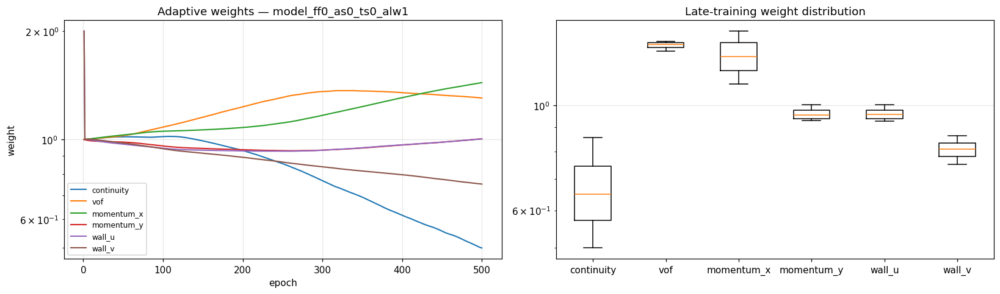

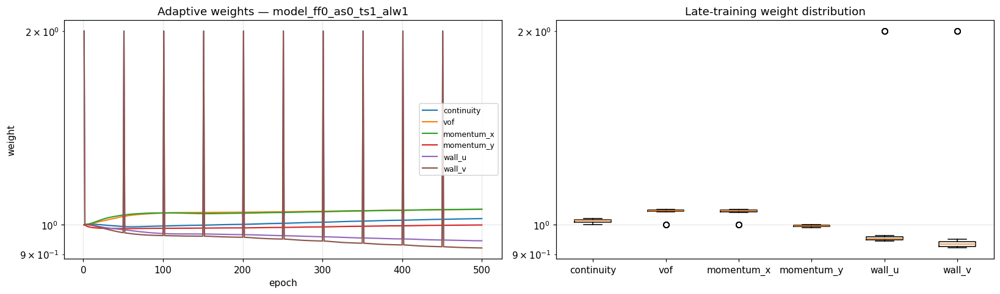

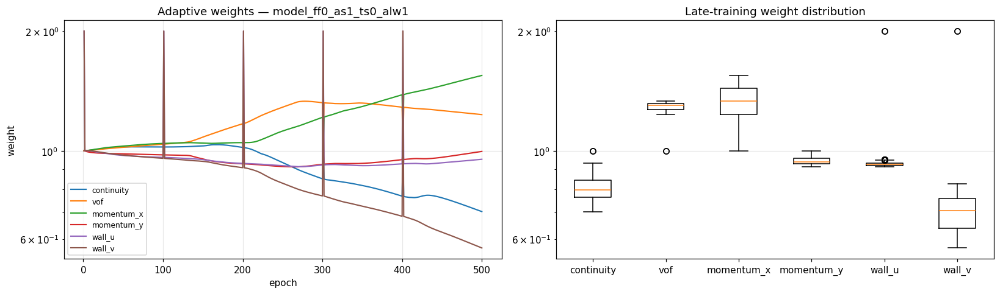

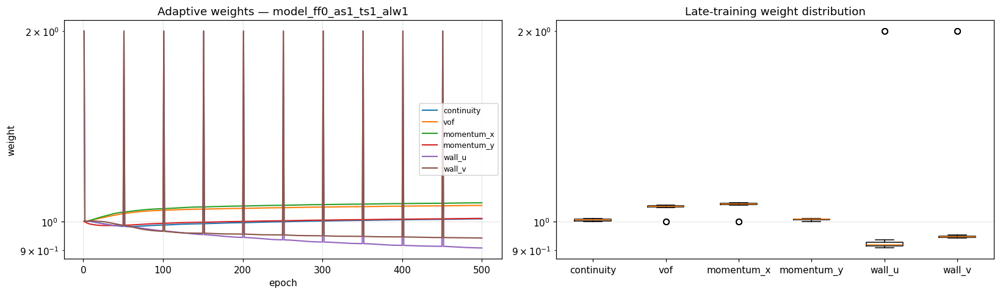

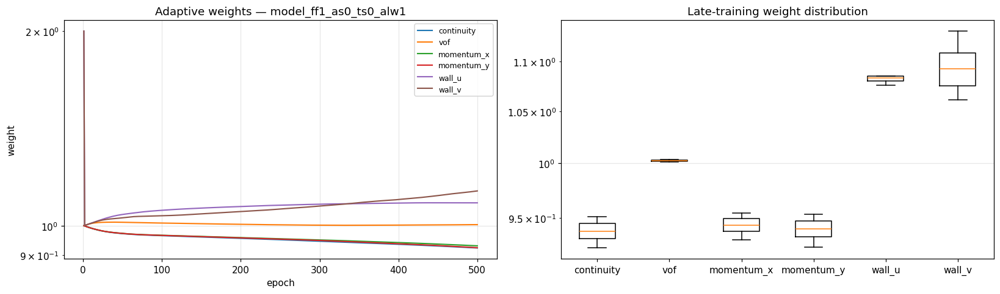

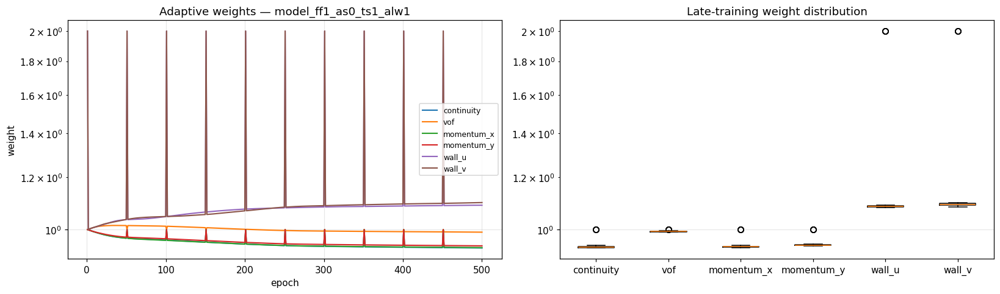

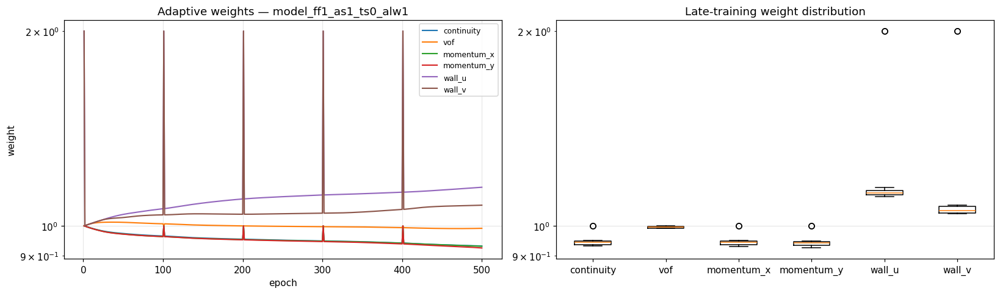

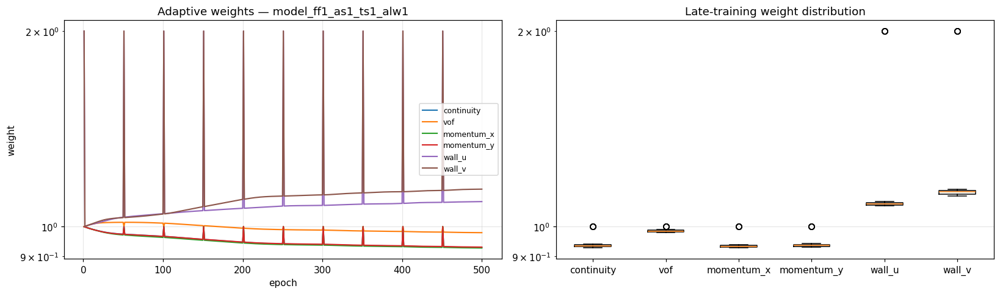

In [14]:
# %%
WEIGHT_RUNS = [b for b in ALL_BITS if b[3] == 1]

def plot_adaptive_weights(bits):
    rdir = ROOT / "models" / combo_name(bits)
    path = rdir / "adaptive_weights.json"
    if not path.is_file():
        print(f"[missing] {path}")
        return None
    data = json.load(open(path))
    df = pd.DataFrame(data)
    fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))

    ax = axes[0]
    for name in ["continuity", "vof", "momentum_x", "momentum_y",
                 "wall_u", "wall_v"]:
        if name in df.columns:
            ax.plot(df["epoch"], df[name], label=name, lw=1.4)
    ax.set_xlabel("epoch")
    ax.set_ylabel("weight")
    ax.set_title(f"Adaptive weights — {combo_name(bits)}")
    ax.set_yscale("log")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)

    ax = axes[1]
    names = [n for n in ["continuity", "vof", "momentum_x",
                         "momentum_y", "wall_u", "wall_v"] if n in df.columns]
    late = df.iloc[len(df) // 2:]
    vals = [late[n].values for n in names]
    try:
        ax.boxplot(vals, tick_labels=names)
    except TypeError:
        ax.boxplot(vals, labels=names)
    ax.set_yscale("log")
    ax.set_title("Late-training weight distribution")
    ax.grid(alpha=0.3, axis="y")
    fig.tight_layout()
    return fig

for bits in WEIGHT_RUNS:
    fig = plot_adaptive_weights(bits)
    if fig is not None:
        plt.show()


## 10. Poids finaux GradNorm (W=1)

Comparaison des `adaptive_weights_final.json` sur les 8 runs `W=1`.

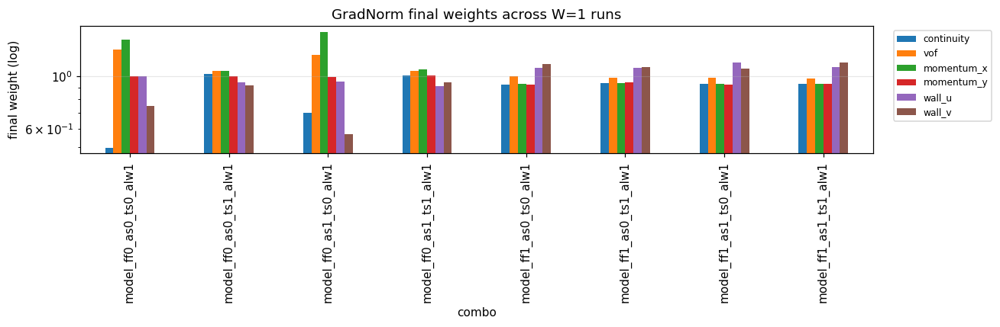

,continuity,vof,momentum_x,momentum_y,wall_u,wall_v
combo,,,,,,
model_ff0_as0_ts0_alw1,0.500,1.303,1.438,1.004,1.004,0.752
model_ff0_as0_ts1_alw1,1.022,1.057,1.057,0.999,0.944,0.920
model_ff0_as1_ts0_alw1,0.703,1.233,1.547,0.996,0.952,0.570
model_ff0_as1_ts1_alw1,1.009,1.060,1.070,1.011,0.908,0.941
model_ff1_as0_ts0_alw1,0.924,1.004,0.931,0.925,1.085,1.132
model_ff1_as0_ts1_alw1,0.938,0.991,0.939,0.945,1.089,1.099
model_ff1_as1_ts0_alw1,0.931,0.991,0.930,0.924,1.147,1.076
model_ff1_as1_ts1_alw1,0.929,0.979,0.927,0.930,1.093,1.142


In [15]:
# %%
final_weights = []
for bits in WEIGHT_RUNS:
    rdir = ROOT / "models" / combo_name(bits)
    p = rdir / "adaptive_weights_final.json"
    if p.is_file():
        w = json.load(open(p))
        w["combo"] = combo_name(bits)
        for fname, b in zip(FEATURE_NAMES, bits):
            w[fname] = int(b)
        final_weights.append(w)

if final_weights:
    fw_df = pd.DataFrame(final_weights).set_index("combo")
    wcols = ["continuity", "vof", "momentum_x", "momentum_y",
             "wall_u", "wall_v"]
    wcols = [c for c in wcols if c in fw_df.columns]

    fig, ax = plt.subplots(figsize=(12, 4))
    fw_df[wcols].plot(kind="bar", ax=ax, logy=True)
    ax.set_ylabel("final weight (log)")
    ax.set_title("GradNorm final weights across W=1 runs")
    ax.grid(alpha=0.3, axis="y")
    ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
    plt.tight_layout()
    plt.show()

    display(fw_df[wcols].style.format(precision=3))


## 11. Points adaptatifs (S=1)

Distribution spatiale des points sélectionnés à différentes époques, et carte du score local.

/tmp/ipykernel_105280/3580529627.py:43: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


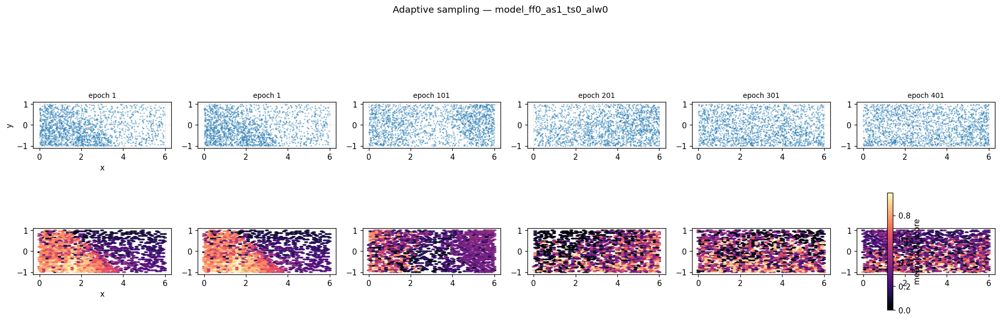

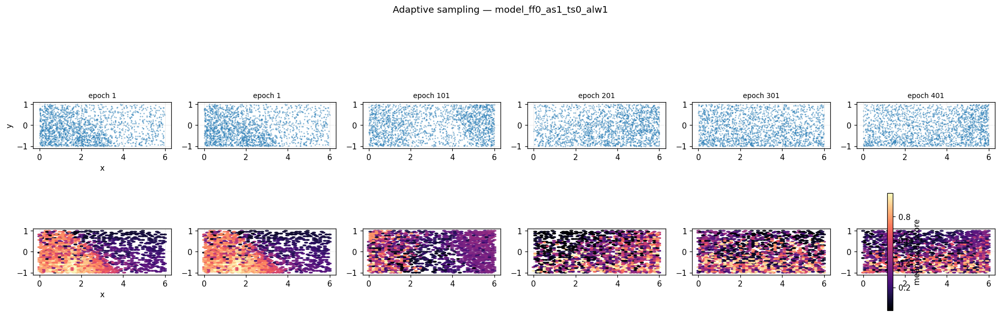

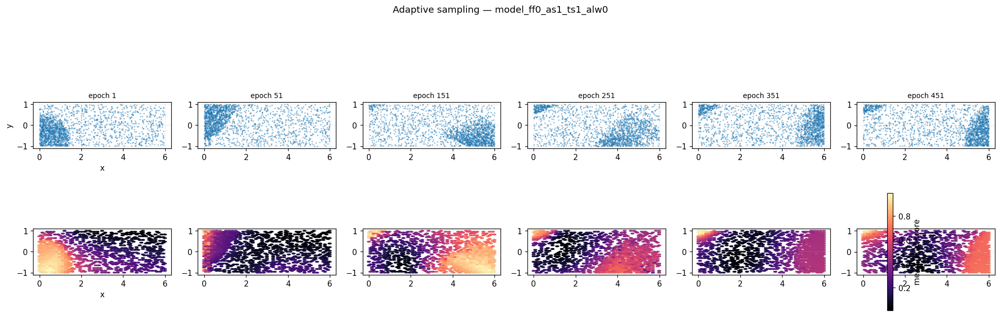

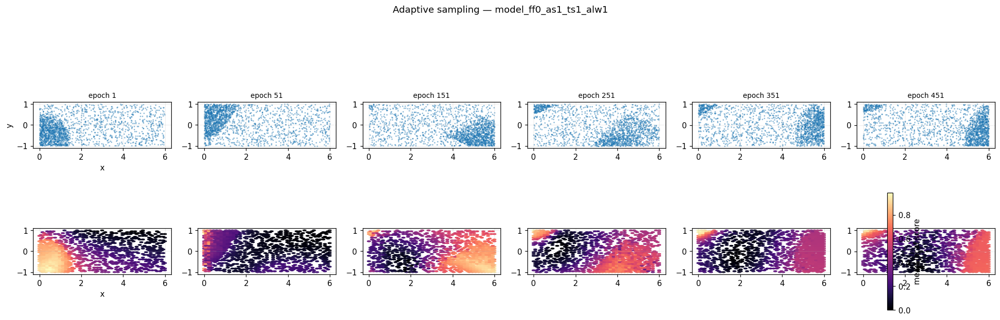

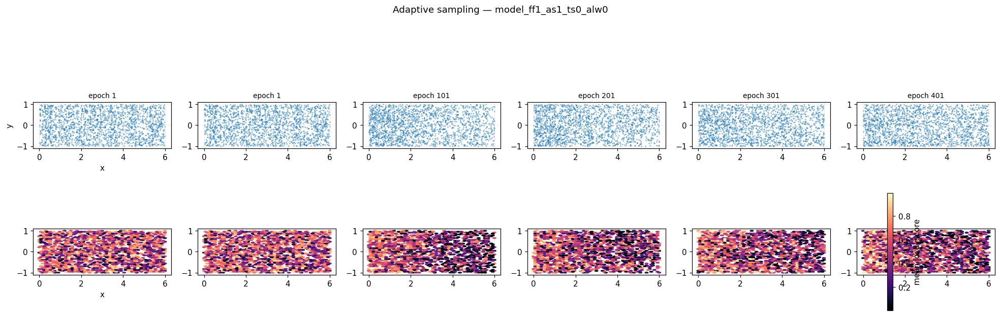

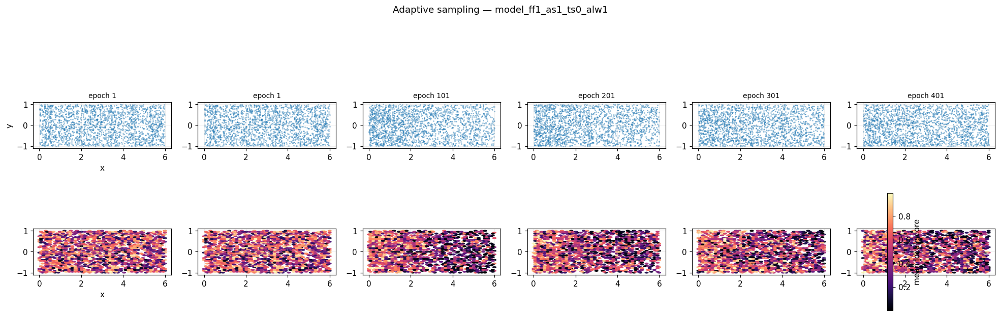

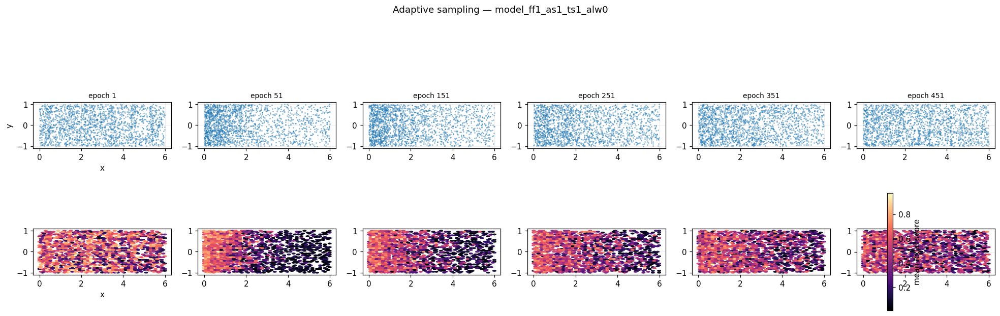

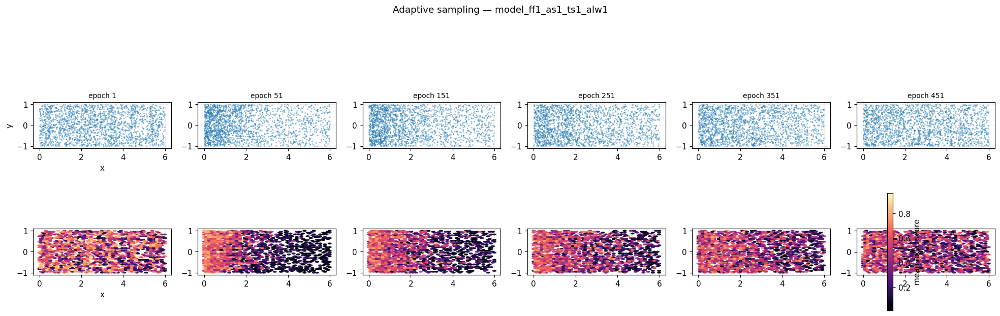

In [16]:
# %%
SAMPLING_RUNS = [b for b in ALL_BITS if b[1] == 1]


def plot_adaptive_points(run_dir, n_show=6, s=1.0, alpha=0.35):
    path = Path(run_dir) / "adaptive_history.npz"
    if not path.is_file():
        print(f"[missing] {path}")
        return None
    data = np.load(path)
    points = data["points"]
    epochs = data["epochs"]
    scores = data["scores"]
    if len(epochs) == 0:
        return None

    idx = np.linspace(0, len(epochs) - 1, n_show).astype(int)

    fig, axes = plt.subplots(2, n_show, figsize=(3.0 * n_show, 6.0))
    for col, i in enumerate(idx):
        ax = axes[0, col]
        pts = points[i]
        ax.scatter(pts[:, 0], pts[:, 1], s=s, alpha=alpha, c="tab:blue")
        ax.set_title(f"epoch {int(epochs[i])}", fontsize=9)
        ax.set_aspect("equal")
        ax.grid(alpha=0.2)
        if col == 0:
            ax.set_ylabel("y")
            ax.set_xlabel("x")

        ax = axes[1, col]
        sc = scores[i]
        ptp = np.ptp(sc)
        scn = (sc - sc.min()) / (ptp + 1e-12) if ptp > 0 else sc * 0
        hb = ax.hexbin(pts[:, 0], pts[:, 1], C=scn, gridsize=40,
                       cmap="magma", reduce_C_function=np.mean, mincnt=1)
        ax.set_aspect("equal")
        ax.grid(alpha=0.2)
        if col == 0:
            ax.set_xlabel("x")
    fig.colorbar(hb, ax=axes[1, :], label="mean local score", fraction=0.02)
    fig.suptitle(f"Adaptive sampling — {Path(run_dir).name}", y=1.02)
    fig.tight_layout()
    return fig


for bits in SAMPLING_RUNS:
    fig = plot_adaptive_points(ROOT / "models" / combo_name(bits))
    if fig is not None:
        plt.show()


## 12. Concentration spatiale des points adaptatifs

Indicateur : coefficient de variation (std/mean) de la densité 2D par histogramme. Plus la valeur est élevée, plus les points se concentrent sur des régions difficiles.

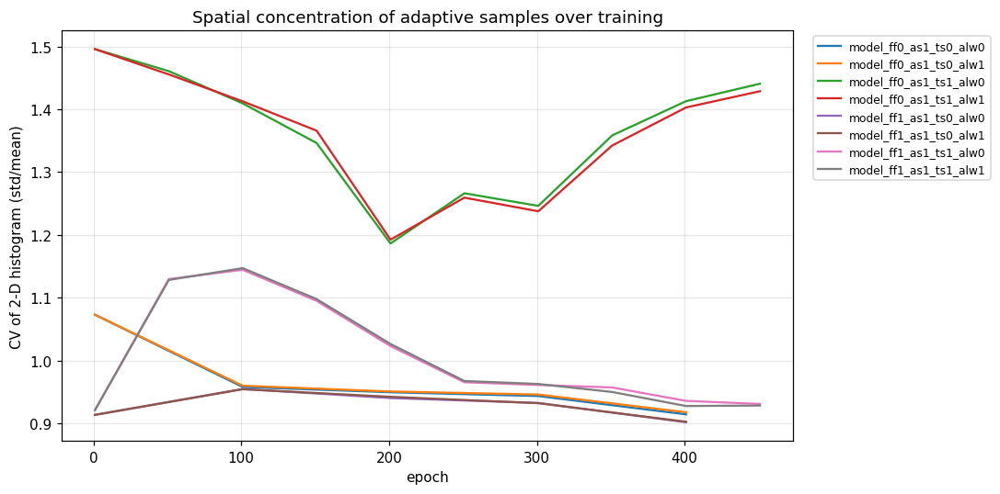

In [18]:
# %%
def concentration_metric(pts, bins=40):
    """CV of 2-D histogram: std/mean over grid cells."""
    if len(pts) < 10:
        return np.nan
    x, y = pts[:, 0], pts[:, 1]
    H, _, _ = np.histogram2d(x, y, bins=bins)
    m = H.mean()
    return float(H.std() / m) if m > 0 else np.nan


fig, ax = plt.subplots(figsize=(10, 5))
for bits in SAMPLING_RUNS:
    p = ROOT / "models" / combo_name(bits) / "adaptive_history.npz"
    if not p.is_file():
        continue
    d = np.load(p)
    epochs = d["epochs"]
    pts_all = d["points"]
    cv = np.array([concentration_metric(pts_all[i]) for i in range(len(epochs))])
    ax.plot(epochs, cv, label=combo_name(bits), lw=1.5)
ax.set_xlabel("epoch")
ax.set_ylabel("CV of 2-D histogram (std/mean)")
ax.set_title("Spatial concentration of adaptive samples over training")
ax.grid(alpha=0.3)
ax.legend(fontsize=8, bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()


## 13. Chargement robuste des modèles entraînés

`train.save_checkpoint` écrit un dict `{"model": state_dict, ...}`. Cette fonction le charge proprement et reconstruit la `Config` depuis le `config.json` sauvegardé.

In [23]:
# %%
def load_trained_model(run_name, device=None):
    rdir = ROOT / "models" / run_name
    device = device or ("cuda" if torch.cuda.is_available() else "cpu")

    model = SloshingPINN(state_path=rdir / "checkpoint_final.pt", config=rdir / "config.json").to(device)
    model.eval()
    return model


## 14. Comparaison physique : baseline vs full

Résidus et champs à un instant intermédiaire, pour `pinn_0000` (aucune feature) et `pinn_1111` (toutes features).

--- Residuals: model_ff0_as0_ts0_alw0 ---


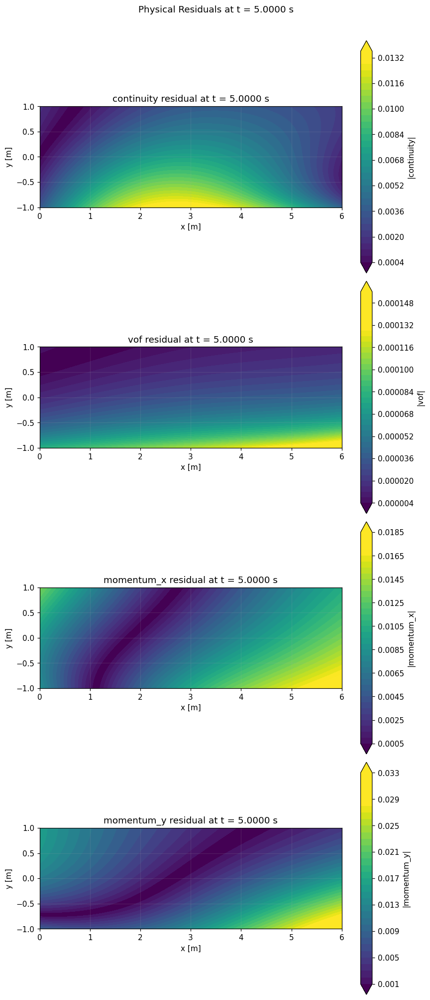

--- Residuals: model_ff1_as1_ts1_alw1 ---


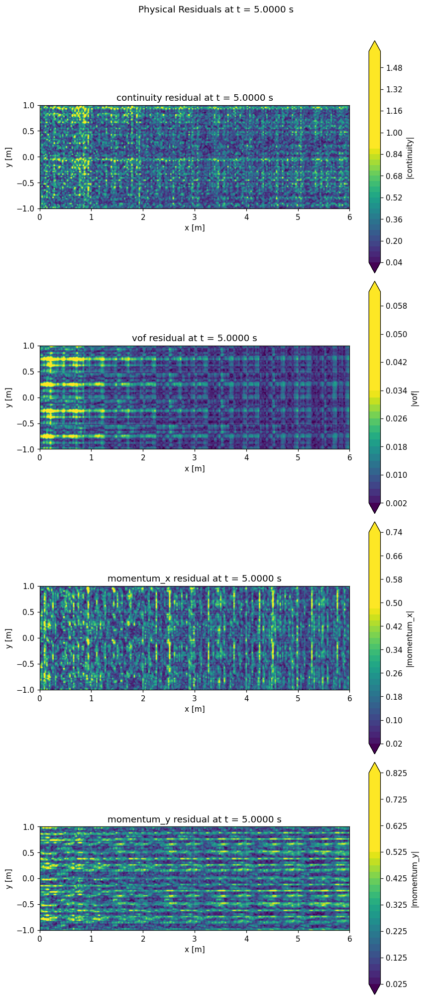

--- Fields: model_ff0_as0_ts0_alw0 ---


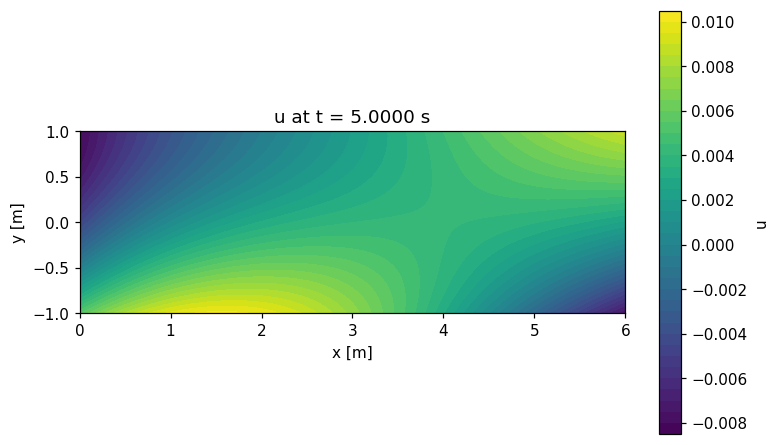

--- Fields: model_ff1_as1_ts1_alw1 ---


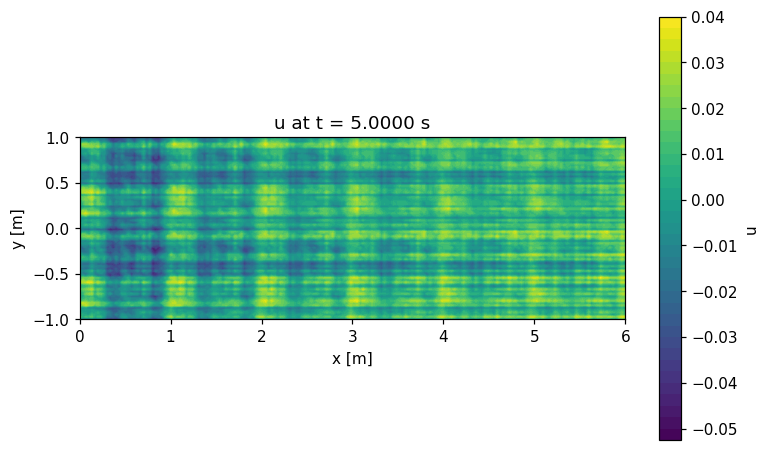

In [24]:
# %%
BASELINE = "model_ff0_as0_ts0_alw0"
FULL = "model_ff1_as1_ts1_alw1"

has_base = (ROOT / "models" / BASELINE / "checkpoint_final.pt").is_file()
has_full = (ROOT / "models" / FULL / "checkpoint_final.pt").is_file()

if has_base and has_full:
    model_base = load_trained_model(BASELINE)
    model_full = load_trained_model(FULL)

    t_probe = 0.5 * float(getattr(model_base.cfg, "t_max", 1.0))

    print(f"--- Residuals: {BASELINE} ---")
    plt.show(plot_residuals(model_base, t=t_probe))

    print(f"--- Residuals: {FULL} ---")
    plt.show(plot_residuals(model_full, t=t_probe))

    print(f"--- Fields: {BASELINE} ---")
    plt.show(plot_fields(model_base, t=t_probe))

    print(f"--- Fields: {FULL} ---")
    plt.show(plot_fields(model_full, t=t_probe))
else:
    print("Missing baseline or full checkpoint — skip.")


## 15. Animation des résidus (optionnel)

Cellule commentée par défaut — l'export `.gif` prend du temps et de l'espace.

In [ ]:
# %%
# from matplotlib.animation import PillowWriter
# model = load_trained_model(FULL)
# t_max = float(getattr(model.cfg, "t_max", 1.0))
# times = np.linspace(float(getattr(model.cfg, "t_min", 0.0)), t_max, 60)
# anim, fig = animate_residuals(
#     model, times, fields=("continuity", "vof"),
#     save_path="residuals_full.gif",
#     display_animation=False,
# )
# print("saved residuals_full.gif")


## 16. Export des tableaux d'analyse

In [ ]:
# %%
EXPORT = OUTPUT_DIR / "analysis"
EXPORT.mkdir(exist_ok=True)

if 'speed_df' in globals():
    speed_df.to_csv(EXPORT / "speed.csv", index=False)
if 'summary_df' in globals():
    summary_df.to_csv(EXPORT / "summary.csv", index=False)
if 'impact_df' in globals():
    impact_df.to_csv(EXPORT / "impact.csv", index=False)

print("Exported to", EXPORT.resolve())


## Notes méthodologiques

1. **Budget contrôlé** : les 16 runs partagent le même `seed`, `epochs`, `n_collocation`, etc. — seule la présence des 4 features change.
2. **Époques comparables** : `epoch` est global (`window_offset + local_epoch + 1`), donc un epoch = un pas d'optimiseur, que `T` soit actif ou non.
3. **Reprise idempotente** : `SKIP_IF_EXISTS=True` rend la cellule Training ré-exécutable sans rien casser.
4. **Smoke-test** : `EPOCHS_OVERRIDE` à `200` pour valider la mécanique, puis `None` pour la config complète.
5. **Stabilité inter-graines** : pour aller plus loin, relancer 2-3 seeds par combo (modifier `seed` dans `make_cfg_from_bits`) et comparer la variance des `final_total`.
6. **Comparaisons honnêtes** : `USE_LBFGS=False` garantit que tous les runs s'arrêtent au même pas d'Adam.
7. **Points de friction connus** :
   - `train.save_checkpoint` renvoie un dict `{"model": state_dict, ...}`, alors que `visualization.load_model` attend un state_dict brut → utiliser `load_trained_model` de la cellule 13.
   - Pour `T=1`, les pertes `initial_*` valent 0 hors de la première fenêtre : c'est attendu.
   - Pour `S=0`, `adaptive_history.npz` n'existe pas : les cellules 11-12 le détectent et sautent.
